# DSA4213 Assignment 1: Part I

**Before you start:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

## 1. Check the GPU

In [ ]:
import torch, subprocess
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"],
                     capture_output=True, text=True).stdout)
assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then rerun."
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

name, memory.total [MiB]
Tesla T4, 15360 MiB

torch 2.11.0+cu130 | GPU: Tesla T4


## 2. Mount Drive and unpack the project
Upload `dsa4213-individual-assignment.zip` to `MyDrive/DSA4213/` first. It is unpacked only once.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os, zipfile
BASE = "/content/drive/MyDrive/DSA4213"
PROJECT = f"{BASE}/dsa4213-individual-assignment"
ZIP = f"{BASE}/dsa4213-individual-assignment.zip"
if not os.path.exists(f"{PROJECT}/src/train.py"):
    assert os.path.exists(ZIP), f"Upload dsa4213-individual-assignment.zip to {BASE}/ first"
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(BASE)
os.chdir(PROJECT)
print("Working in", os.getcwd()); print(sorted(os.listdir()))

Working in /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment
['.git', '.ipynb_checkpoints', 'README.md', 'configs', 'data', 'requirements.txt', 'results', 'src']


## 3. Install the missing package: gensim


In [ ]:
!pip -q install gensim
import numpy, pandas, gensim, sklearn
print("numpy", numpy.__version__, "| pandas", pandas.__version__,
      "| gensim", gensim.__version__, "| sklearn", sklearn.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 72.7 MB/s eta 0:00:00
numpy 2.1.3 | pandas 2.2.3 | gensim 4.4.0 | sklearn 1.6.1


## 4. Download the dataset and GloVe (skipped if already in Drive)

In [ ]:
%%bash
set -e
mkdir -p data/raw data/glove
if [ ! -f data/raw/medical_tc_train.csv ]; then
  git clone -q --depth 1 https://github.com/sebischair/Medical-Abstracts-TC-Corpus.git /tmp/matc
  cp /tmp/matc/medical_tc_*.csv data/raw/
fi
if [ ! -f data/glove/glove-wiki-gigaword-200.gz ]; then
  curl -sSL -o data/glove/glove-wiki-gigaword-200.gz \
    https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-200/glove-wiki-gigaword-200.gz
fi
ls -la data/raw data/glove

data/glove:
total 258150
drwx------ 2 root root      4096 Oct 11 03:12 .
drwx------ 4 root root      4096 Oct 11 03:12 ..
-rw------- 1 root root 264336934 Oct 11 03:12 glove-wiki-gigaword-200.gz

data/raw:
total 17432
drwx------ 2 root root     4096 Oct 11 03:12 .
drwx------ 4 root root     4096 Oct 11 03:12 ..
-rw------- 1 root root      157 Oct 11 03:12 medical_tc_labels.csv
-rw------- 1 root root  3586836 Oct 11 03:12 medical_tc_test.csv
-rw------- 1 root root 14254503 Oct 11 03:12 medical_tc_train.csv


## 5. Step 1: data pipeline

In [ ]:
!python -m src.data_preparation --config configs/data.yaml --coverage-check
!python -m src.data_preparation --config configs/data.yaml

Split stats: {'raw_train_rows': 11550, 'raw_test_rows': 2888, 'unique_train_abstracts': 9445, 'unique_test_abstracts': 2770, 'train_abstracts_also_in_test_removed': 988, 'unique_abstracts_total': 11227, 'train_abstracts': 7611, 'train_single_label_abstracts': 5946, 'val_abstracts': 846, 'val_single_label_abstracts': 661, 'test_abstracts': 2770, 'test_single_label_abstracts': 1691}
GloVe loaded: 400,000 words x 200d (4.3s)

[joined] vocab=19,092  train tokens=1,574,623  val <unk>=3.01%  hyphenated types=8,679
   GloVe overall : types 74.8%  tokens 97.7%  (n types=19,088)
   GloVe frequent: types 100.0%  tokens 100.0%  (n types=154)
   GloVe medium  : types 98.5%  tokens 99.3%  (n types=2,672)
   GloVe rare    : types 70.7%  tokens 82.0%  (n types=16,262)

[split] vocab=17,645  train tokens=1,603,305  val <unk>=2.30%  hyphenated types=0
   GloVe overall : types 79.5%  tokens 98.1%  (n types=17,641)
   GloVe frequent: types 100.0%  tokens 100.0%  (n types=164)
   GloVe medium  : types 98.

## 6. Step 2: trigram baseline

In [ ]:
!python -m src.ngram --config configs/ngram.yaml

Fit 0.1s | tuning 0.6s | weights (l1,l2,l3) = (0.2, 0.45, 0.35)
Val PPL 146.62 | Test CE 4.9659 | Test PPL 143.43
Throughput 1,281,112 tokens/s | size {'unigram_entries': 17644, 'bigram_entries': 368174, 'trigram_entries': 935905, 'stored_ngram_entries': 1321723, 'memory_mb': 25.92041778564453}
Test CE by bucket: {'frequent': 3.227, 'medium': 6.763, 'rare': 10.374, 'unk': 4.307, 'special': 1.93}
Top-5 weight settings on val:
   l1   l2   l3   val_ce
0.20 0.45 0.35 4.987834
0.25 0.45 0.30 4.988250
0.25 0.40 0.35 4.988833
0.20 0.50 0.30 4.989251
0.20 0.40 0.40 4.990776


## 7. Train the neural models
A model is skipped if its training already finished. If Colab disconnects in the middle of a model, rerunning its cell retrains that model from scratch.

In [ ]:
import json, os, subprocess, sys

def train(name):
    log = f"results/part1_{name}/train_log.json"
    if os.path.exists(log) and "epochs_run" in json.load(open(log)):
        print(f"part1_{name} already trained, skipping"); return
    # Stream the training output live.
    proc = subprocess.Popen([sys.executable, "-m", "src.train", "--config",
                             f"configs/part1_{name}.yaml"],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    assert proc.wait() == 0, f"training {name} failed"

In [ ]:
train("rnn")

[part1_rnn] device=cuda params={'total': 8312597, 'trainable': 8312597, 'token_embedding': 3529000, 'positional_embedding': 0, 'output_layer': 4534765, 'core_non_embedding': 248832}
  epoch  1  train CE 7.4508  val CE 6.1675 (PPL  477.00)    18.4s  *best
  epoch  2  train CE 5.9736  val CE 5.4993 (PPL  244.51)    17.6s  *best
  epoch  3  train CE 5.5809  val CE 5.2654 (PPL  193.53)    18.4s  *best
  epoch  4  train CE 5.3845  val CE 5.1277 (PPL  168.62)    19.3s  *best
  epoch  5  train CE 5.2514  val CE 5.0317 (PPL  153.19)    20.5s  *best
  epoch  6  train CE 5.1493  val CE 4.9581 (PPL  142.33)    19.7s  *best
  epoch  7  train CE 5.0672  val CE 4.8994 (PPL  134.22)    19.2s  *best
  epoch  8  train CE 4.9985  val CE 4.8544 (PPL  128.30)    19.6s  *best
  epoch  9  train CE 4.9400  val CE 4.8086 (PPL  122.55)    19.9s  *best
  epoch 10  train CE 4.8913  val CE 4.7802 (PPL  119.12)    19.8s  *best
  epoch 11  train CE 4.8464  val CE 4.7528 (PPL  115.91)    19.6s  *best
  epoch 12  tra

In [ ]:
train("lstm")

[part1_lstm] device=cuda params={'total': 9059093, 'trainable': 9059093, 'token_embedding': 3529000, 'positional_embedding': 0, 'output_layer': 4534765, 'core_non_embedding': 995328}
  epoch  1  train CE 7.5415  val CE 6.6233 (PPL  752.43)    22.3s  *best
  epoch  2  train CE 6.6449  val CE 6.2225 (PPL  503.98)    23.3s  *best
  epoch  3  train CE 6.2121  val CE 5.8910 (PPL  361.77)    24.6s  *best
  epoch  4  train CE 5.9402  val CE 5.6579 (PPL  286.54)    23.1s  *best
  epoch  5  train CE 5.7405  val CE 5.4806 (PPL  239.99)    23.4s  *best
  epoch  6  train CE 5.5804  val CE 5.3467 (PPL  209.92)    23.9s  *best
  epoch  7  train CE 5.4602  val CE 5.2527 (PPL  191.08)    23.6s  *best
  epoch  8  train CE 5.3648  val CE 5.1715 (PPL  176.17)    23.3s  *best
  epoch  9  train CE 5.2850  val CE 5.1043 (PPL  164.73)    23.8s  *best
  epoch 10  train CE 5.2147  val CE 5.0499 (PPL  156.01)    23.9s  *best
  epoch 11  train CE 5.1517  val CE 4.9949 (PPL  147.66)    23.5s  *best
  epoch 12  tr

In [ ]:
train("transformer")

[part1_transformer] device=cuda params={'total': 8066845, 'trainable': 8066845, 'token_embedding': 3529000, 'positional_embedding': 25600, 'output_layer': 3546645, 'core_non_embedding': 965600}
  epoch  1  train CE 7.3255  val CE 5.8859 (PPL  359.93)    19.5s  *best
  epoch  2  train CE 5.7245  val CE 5.3583 (PPL  212.36)    19.7s  *best
  epoch  3  train CE 5.3718  val CE 5.1860 (PPL  178.76)    20.0s  *best
  epoch  4  train CE 5.1823  val CE 5.0824 (PPL  161.16)    20.3s  *best
  epoch  5  train CE 5.0471  val CE 5.0028 (PPL  148.83)    20.8s  *best
  epoch  6  train CE 4.9402  val CE 4.9374 (PPL  139.41)    21.1s  *best
  epoch  7  train CE 4.8539  val CE 4.8856 (PPL  132.37)    21.5s  *best
  epoch  8  train CE 4.7812  val CE 4.8368 (PPL  126.06)    21.6s  *best
  epoch  9  train CE 4.7182  val CE 4.8002 (PPL  121.54)    21.8s  *best
  epoch 10  train CE 4.6651  val CE 4.7748 (PPL  118.49)    22.0s  *best
  epoch 11  train CE 4.6175  val CE 4.7513 (PPL  115.73)    22.2s  *best
  e

## 8. Evaluate, generate text, run the correctness checks, build tables and figures

In [ ]:
!python -m src.evaluate --runs part1_rnn part1_lstm part1_transformer
!python -m src.generate --config configs/generate.yaml
!python -m src.checks
!python -m src.analyze_results

[part1_rnn] test CE 4.5325  PPL 92.99  260,133 tok/s  buckets {'frequent': 2.83, 'medium': 6.29, 'rare': 9.73, 'unk': 4.28, 'special': 1.54}
[part1_lstm] test CE 4.5278  PPL 92.55  217,930 tok/s  buckets {'frequent': 2.78, 'medium': 6.38, 'rare': 9.72, 'unk': 4.16, 'special': 1.52}
[part1_transformer] test CE 4.5085  PPL 90.79  264,500 tok/s  buckets {'frequent': 2.9, 'medium': 6.06, 'rare': 9.75, 'unk': 4.68, 'special': 1.56}
n-gram       distinct-2 0.967  rep-3gram 0.001  <unk> 0.021  1642.2 tok/s
RNN          distinct-2 0.961  rep-3gram 0.003  <unk> 0.016  566.4 tok/s
LSTM         distinct-2 0.956  rep-3gram 0.007  <unk> 0.029  656.7 tok/s
Transformer  distinct-2 0.922  rep-3gram 0.019  <unk> 0.006  331.3 tok/s
wrote /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/results/generation/samples.md
causality rnn                                           OK  max change before t = 0.00e+00
causality lstm                                          OK  max change before t = 0.00e+

## 9. Look at the results

# Part I results

Common evaluation: 585,134 test targets (padding excluded), identical for every model.

## Quality and cost

| Model       |   Test CE |   Test PPL | PPL 95% CI       |   Val PPL | Params (total)           | Core params   |   Train time (min) |   Time to best (min) | Epochs (best/run)   |   Size (MB) |   Scoring tok/s | Device   |   Generation tok/s |
|:------------|----------:|-----------:|:-----------------|----------:|:-------------------------|:--------------|-------------------:|---------------------:|:--------------------|------------:|----------------:|:---------|-------------------:|
| n-gram      |     4.966 |     143.4  | [140.94, 145.80] |    146.6  | 1,321,723 n-gram entries | -             |              0.002 |                0.012 | -                   |        25.9 |         1281112 | Tesla T4 |             1642   |
| RNN         |     4.532 |      92.99 | [91.38, 94.59]   |     94.57 | 8,312,597                | 248,832       |             13.12  |               13.12  | 40/40               |        31.7 |          260133 | cuda     |              566.4 |
| LSTM        |     4.528 |      92.55 | [91.00, 94.12]   |     94.21 | 9,059,093                | 995,328       |             15.84  |               15.84  | 40/40               |        34.6 |          217930 | cuda     |              656.7 |
| Transformer |     4.508 |      90.79 | [89.09, 92.42]   |     92.81 | 8,066,845                | 965,600       |             14.96  |               14.58  | 39/40               |        30.8 |          264500 | cuda     |              331.3 |

Train time = wall-clock training (n-gram: counting). Time to best = up to the checkpoint used for evaluation. Scoring tok/s = common workload (all test targets, 128-token blocks). Check the Device column before comparing times.

## Paired bootstrap: test CE difference (A - B), 95% CI over blocks

| model_a   | model_b     |   ce_a_minus_b |   ci_low |   ci_high | ci_excludes_zero   |
|:----------|:------------|---------------:|---------:|----------:|:-------------------|
| n-gram    | RNN         |         0.4334 |   0.4281 |    0.4386 | True               |
| n-gram    | LSTM        |         0.4381 |   0.4320 |    0.4439 | True               |
| n-gram    | Transformer |         0.4573 |   0.4514 |    0.4633 | True               |
| RNN       | LSTM        |         0.0047 |   0.0019 |    0.0073 | True               |
| RNN       | Transformer |         0.0239 |   0.0189 |    0.0288 | True               |
| LSTM      | Transformer |         0.0192 |   0.0134 |    0.0251 | True               |

## Test CE by frequency bucket

| Bucket                        |   Share of targets |   n-gram |   RNN |   LSTM |   Transformer |
|:------------------------------|-------------------:|---------:|------:|-------:|--------------:|
| frequent                      |              0.525 |    3.227 | 2.834 |  2.777 |         2.904 |
| medium                        |              0.312 |    6.763 | 6.288 |  6.385 |         6.059 |
| rare                          |              0.094 |   10.374 | 9.734 |  9.722 |         9.747 |
| unk                           |              0.022 |    4.307 | 4.284 |  4.164 |         4.679 |
| general words (GloVe top-50k) |              0.850 |    4.761 | 4.335 |  4.327 |         4.334 |
| domain words                  |              0.081 |    9.065 | 8.415 |  8.495 |         8.014 |

## Test CE by position in block

| Positions   |   Targets |   n-gram |   RNN |   LSTM |   Transformer |
|:------------|----------:|---------:|------:|-------:|--------------:|
| 0           |      4572 |    5.079 | 5.221 |  5.241 |         5.301 |
| 1           |      4572 |    5.041 | 4.974 |  5.020 |         5.075 |
| 2-3         |      9144 |    4.946 | 4.736 |  4.780 |         4.829 |
| 4-7         |     18288 |    4.964 | 4.618 |  4.654 |         4.696 |
| 8-15        |     36576 |    4.983 | 4.569 |  4.584 |         4.609 |
| 16-31       |     73152 |    4.944 | 4.513 |  4.514 |         4.509 |
| 32-63       |    146286 |    4.971 | 4.521 |  4.511 |         4.492 |
| 64-127      |    292544 |    4.964 | 4.509 |  4.498 |         4.461 |

## Generated text metrics (25 samples x 50 tokens per model)

| Model       |   distinct_1 |   distinct_2 |   repeated_trigram_rate |   unk_rate |   num_rate |   generation_tokens_per_second |
|:------------|-------------:|-------------:|------------------------:|-----------:|-----------:|-------------------------------:|
| n-gram      |        0.673 |        0.967 |                   0.001 |      0.021 |      0.090 |                       1642.153 |
| RNN         |        0.740 |        0.961 |                   0.003 |      0.016 |      0.040 |                        566.382 |
| LSTM        |        0.717 |        0.956 |                   0.007 |      0.029 |      0.062 |                        656.662 |
| Transformer |        0.676 |        0.922 |                   0.019 |      0.006 |      0.052 |                        331.281 |

Side-by-side samples: results/generation/samples.md



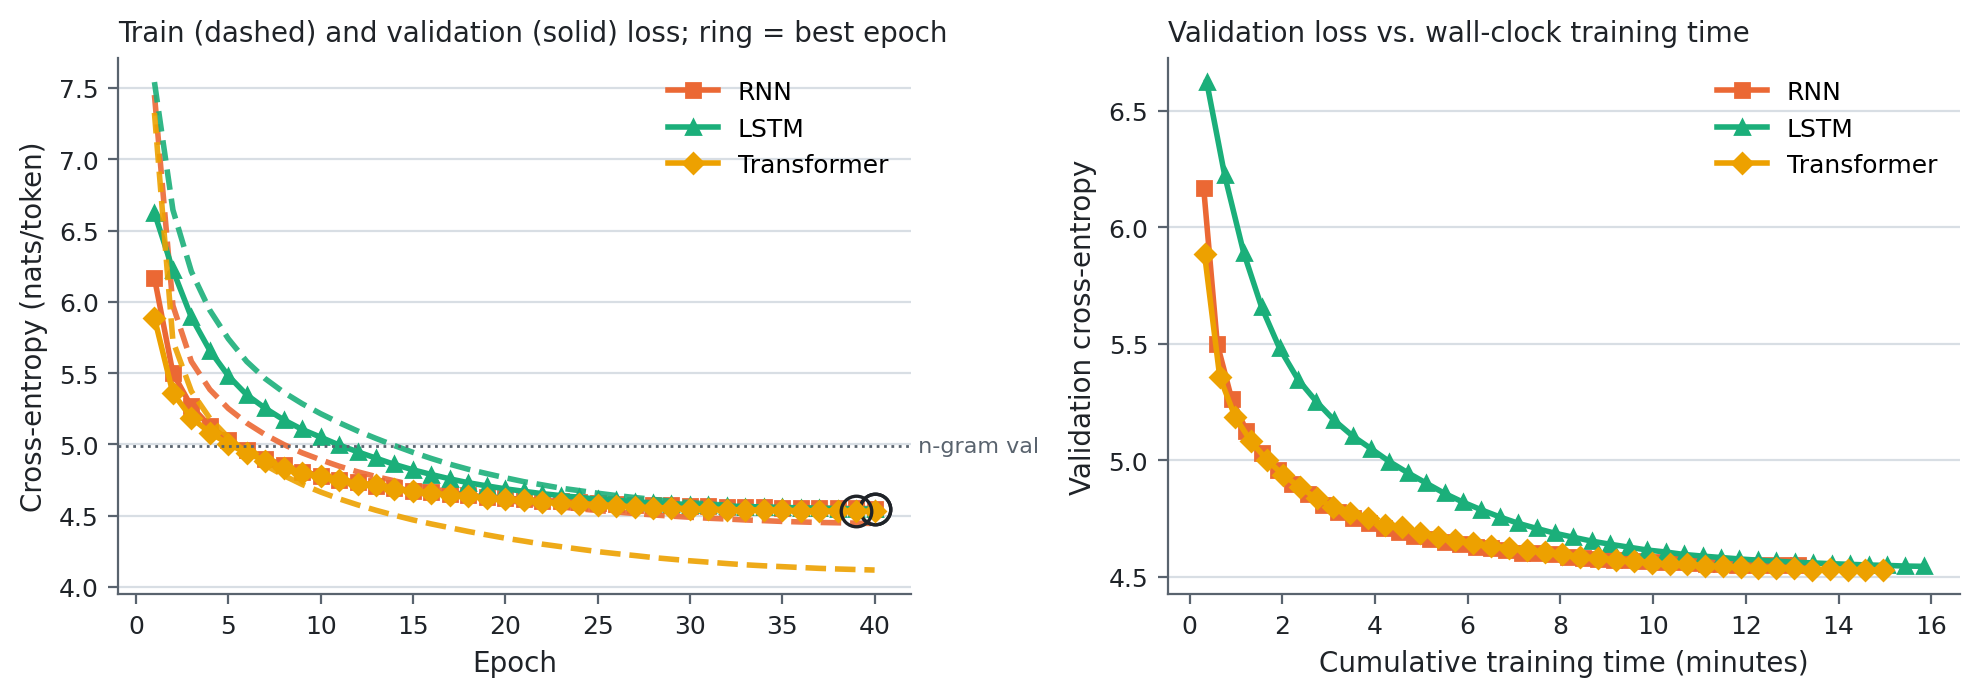

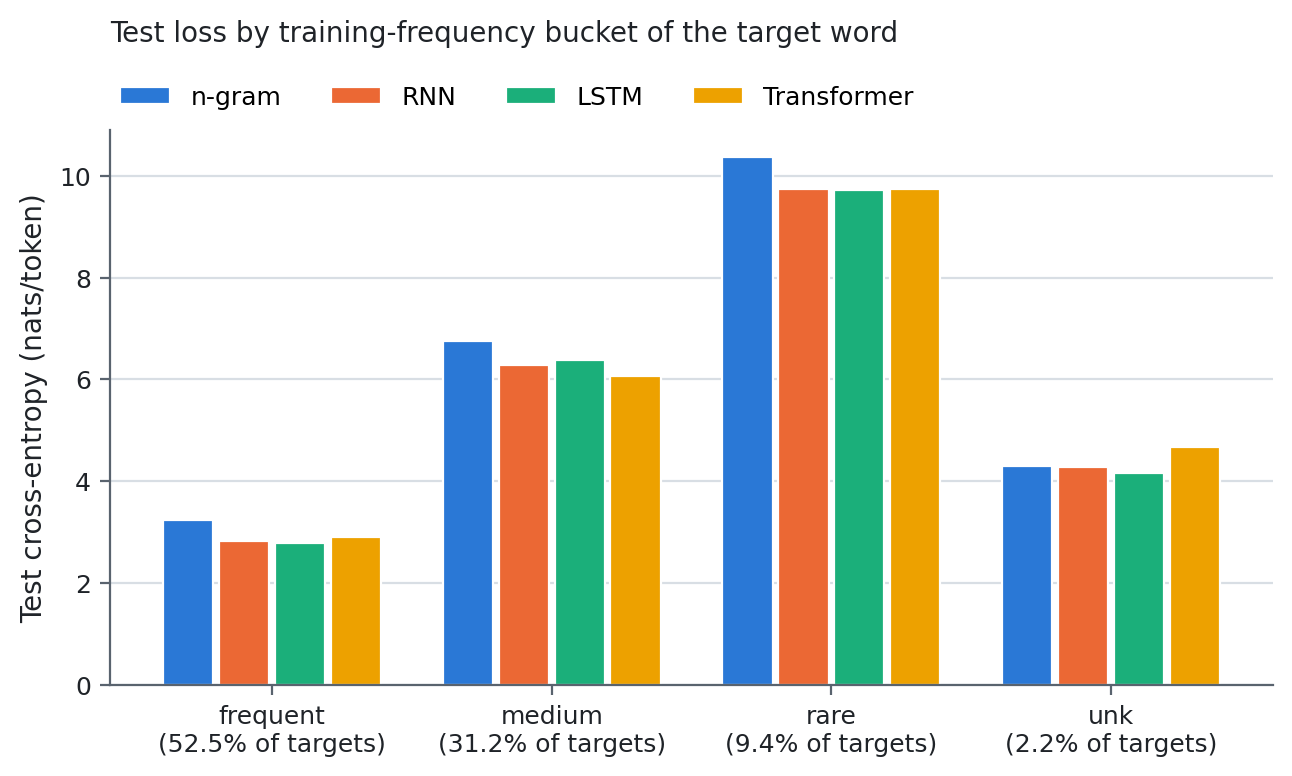

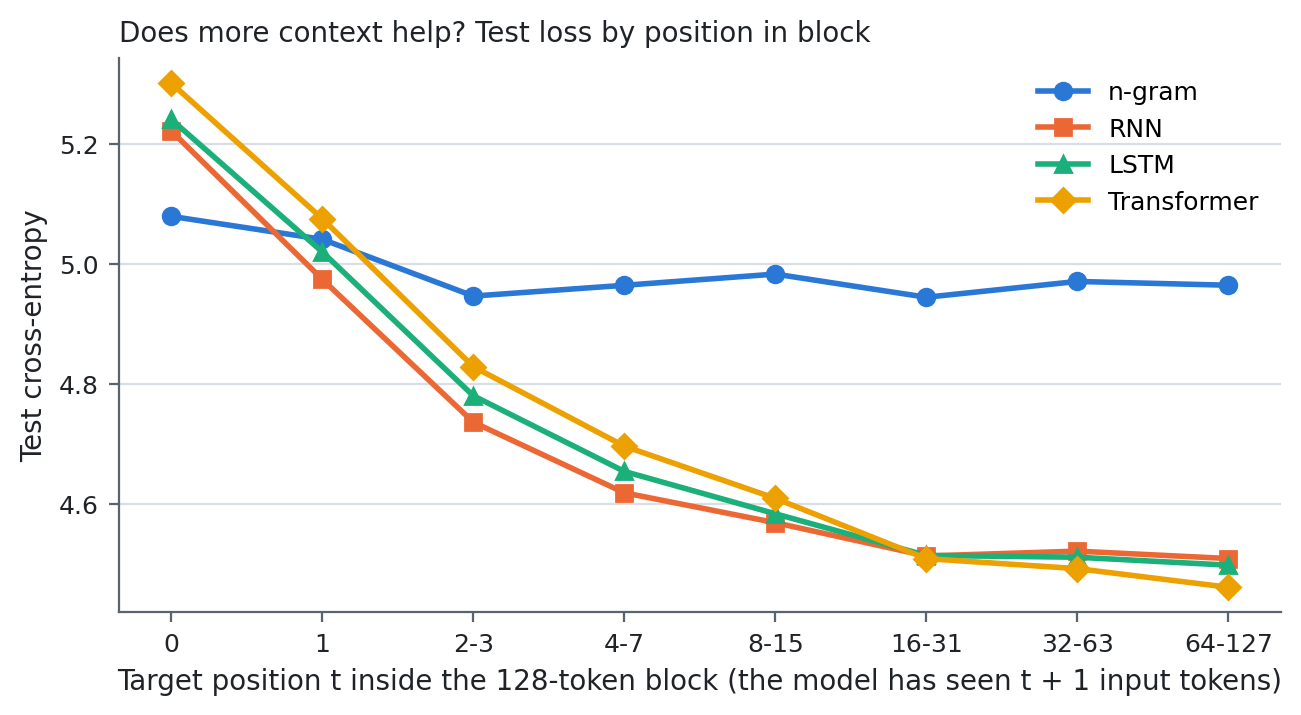

In [ ]:
from IPython.display import Markdown, Image, display
display(Markdown(open("results/part1/summary.md").read().split("## Figures")[0]))
for fig in ["fig_loss_curves", "fig_bucket_ce", "fig_position_ce"]:
    display(Image(f"results/part1/{fig}.png"))

In [ ]:
display(Markdown(open("results/generation/samples.md").read()))

# Generated continuations (temperature 1.0, top-k 40, 50 new tokens, sample 0)

## Prompt 1 (neoplasms): *treatment of childhood &lt;unk&gt; diseases with recombinant interferon*

| Model | Continuation |
|---|---|
| n-gram | alfa 2a as outpatient therapy. despite normal basic drive,. &lt;num&gt;). &lt;num&gt; year old man experienced of the &lt;num&gt; per &lt;num&gt; (&lt;num&gt;), and the presence in mucosa inflamed because) at the onset with bradykinesia. in the diagnosis between tumor histologic evidence |
| RNN | alfa 2a after induction of the novacor defect (osa). in the &lt;num&gt; of cases were investigated prospectively. in &lt;num&gt; children. in the study, the effect of indomethacin (vp &lt;num&gt;) had a mild stroke effects. in &lt;num&gt; patients undergoing angioplasty were followed |
| LSTM | alfa and alpha subunit and &lt;unk&gt; antibodies (tnf). the case of &lt;unk&gt; &lt;unk&gt; t cells is thought to be a potent &lt;unk&gt; and the presence of an inflammatory component that may involve a deletion from the regulation of chromosome &lt;num&gt;. the gene encoding the cellular reaction |
| Transformer | alfa 2a after intravenous heparin. sixty eight children undergoing a &lt;num&gt; year period. the remaining patient underwent orthotopic heart surgery, four of &lt;num&gt; patients had acute myocardial infarction or cardiogenic shock complicated cardiac catheterization had acute stroke at least &lt;num&gt; years. all deaths from whom underwent |

## Prompt 2 (digestive system diseases): *appraisal of gut lavage in the study of*

| Model | Continuation |
|---|---|
| n-gram | &lt;num&gt; consecutive patients. &lt;unk&gt; and the &lt;num&gt; patients with a second, p less than with (&lt;unk&gt;, &lt;num&gt;, n &lt;num&gt; cases in a mean of &lt;num&gt; was seen in &lt;num&gt;%) by means of the patients with severe and &lt;unk&gt;. in the other hand |
| RNN | the choroid plexus. &lt;unk&gt; and to be associated with a diffuse cell lymphoma with an autosomal dominant &lt;unk&gt; of the human retinoblastoma. there is a single increase of tumor suppressor genes. we conclude that it is also used for some of &lt;num&gt;, and in other organs |
| LSTM | the pathophysiology of &lt;unk&gt; &lt;unk&gt;. a patient with an abnormal extremity, or one patient developed a &lt;unk&gt;, the patient underwent &lt;unk&gt; syndrome and in a patient. an unusual model of cancer had been diagnosed by the use of surgical diagnosis. the most common lesion identified |
| Transformer | &lt;num&gt; diabetic patients. the incidence of the breast cancer was investigated in the elderly patients who had &lt;num&gt; patients, &lt;num&gt; women. twenty six patients had more patients had undergone mastectomy, were randomly assigned to receive either primary breast cancer. the patients had breast cancer received |

## Prompt 3 (nervous system diseases): *expression of neural cell adhesion molecule in normal*

| Model | Continuation |
|---|---|
| n-gram | . there were in group p less than that of arteries, neural structures. five year &lt;unk&gt; of the &lt;num&gt; &lt;num&gt;, or greater. we examined in this study of doxazosin treatment (in vitro after treatment with the &lt;unk&gt; to the mean, (&lt;num&gt;%. |
| RNN | and neoplastic tissues. we conclude that this concept was inhibited that they do not contain specific &lt;unk&gt;. these results are associated with higher than that in human immunodeficiency virus, suggesting that in some t cells are discussed. the relationship of human t lymphocytes and antigen of |
| LSTM | . we report the efficacy of an unusual locus of murine liver lymphoma with &lt;num&gt; amino acids &lt;unk&gt;. with the &lt;unk&gt; of these areas of a large brain type, the polymerase chain reaction was determined by two fold, &lt;unk&gt; and &lt;num&gt; h of c. e &lt;num&gt; |
| Transformer | patients with advanced breast cancer of cancer of colorectal cancer associated with colorectal cancer. we investigated &lt;num&gt; patients with cancer. the authors conducted the authors reviewed the prevalence of the danish cohort of carcinoma patients from an inverse correlation of breast cancer patients with squamous cell carcinoma. |

## Prompt 4 (cardiovascular diseases): *bolus, front loaded, and accelerated thrombolytic*

| Model | Continuation |
|---|---|
| n-gram | therapy for acute of this, was associated with a &lt;num&gt; and &lt;num&gt; &lt;num&gt; year survival rates of the tumor markers in two of the &lt;num&gt; patients, the patient recovered agent, of the and &lt;num&gt;). no such a, which (% and the effects of |
| RNN | therapy with continuous &lt;num&gt; fluorouracil. a new technique for the treatment of the procedure or absence of the abdominal cavity for treatment of cancer. these results suggest that many other agents is not different. to determine whether a patient with acute myocardial infarction, we examined the |
| LSTM | procedures (ct) than the control of the central aorta. the &lt;num&gt; children with obstructive hypertension in one series and two with normal and three patients with primary hyperparathyroidism were studied. in the treatment of the head and the disease in the same group, these other |
| Transformer | therapy for recurrent acute osteomyelitis. this case report describes the most acute myocardial infarction was admitted to an unusual problem in patients. this study suggests that the role as an effective drug therapy to have an important problem in the risk factor in an important role of severe |

## Prompt 5 (general pathological conditions): *the importance of congenital hypertrophy of the retinal*

| Model | Continuation |
|---|---|
| n-gram | artery occlusion, the patients with low level the odds of their movement of the in vitro and in &lt;num&gt; patients with a small cell lung carcinoma), and &lt;num&gt; months) was. to &lt;num&gt; days for the disease. no serious complications of &lt;unk&gt; were performed in |
| RNN | vein from the left anterior descending carotid artery. in &lt;num&gt; patients who had no evidence of this complication in the management of hypertension, an underlying complication of the patient's syndrome may be diagnosed. although all patients were treated by debridement of the &lt;unk&gt;'s procedure. |
| LSTM | artery. in &lt;num&gt; patients with congestive heart disease, &lt;num&gt; patients underwent a total of &lt;num&gt; patients from &lt;num&gt; patients with severe angina (&lt;num&gt;%). in the elderly patients (&lt;num&gt;%) compared with &lt;num&gt; patients and all died, the &lt;unk&gt; group were more |
| Transformer | artery (lv) and pulmonary artery disease. to this rare event in a case is presented, and pulmonary artery stenosis at a severe arterial aneurysms. an aneurysm has been shown to be a unique complication of a clinical entity involving the case. it is reported |


## 10. Download the results (optional; they are also in Drive)

In [ ]:
import shutil
shutil.make_archive("/content/part1_results_run2", "zip", root_dir=PROJECT, base_dir="results")
!cd /content && zip -q -d part1_results_run2.zip "results/*/best.pt" "results/ngram/model.npz" || true
from google.colab import files
files.download("/content/part1_results_run2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>